# GATA3, IKZF2 and TBX21 expression across AMP CD4 subsets in the T + F CTAP

Documents `GATA3`, `IKZF2` (Helios) and `TBX21` (T-bet) expression across the AMP 2023 CD4 subsets of
the `T + F` CTAP, then compares T-7 (IFNG+ Tph/Tfh), T-3 (IFNG- Tph/Tfh) and T-4 (naive) between RA
`T + F` biopsies and osteoarthritis controls.

- **Scope:** `T + F` CTAP RA biopsies plus all OA controls (`CTAP = "control"`), as in `01`-`03`.
- **Expression:** `log1p_norm` values. Genes are sparse (IKZF2 especially), so means are low and
  many cells are zero.
- **Statistics:** the replicate is the donor x subset profile (>= `MIN_CELLS_PER_PSEUDOBULK`
  cells). RA vs control within each subset compares different donors (Mann-Whitney U),
  BH-corrected across the three subsets for each gene.

## 1. Imports and parameters

In [32]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
from itertools import combinations
from scipy import stats
from statsmodels.stats.multitest import multipletests

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import cnsplots as cns
cns.settings.panel_label_fontname = "sans serif"

plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["text.usetex"] = False
sc.settings.verbosity = 1

# Repo-relative paths (inputs: imports_stable/, outputs: analysis_outs/)
from pathlib import Path
_here = Path.cwd().resolve()
REPO_DIR = str(next(p for p in [_here, *_here.parents] if (p / "imports_stable").is_dir()))
IMPORTS_DIR = f"{REPO_DIR}/imports_stable"
OUTS_DIR = f"{REPO_DIR}/analysis_outs/03_activity_inference_model"

# ---- inputs
AMP_H5AD = f"{IMPORTS_DIR}/external/AMP_2023/amp_2023_cd4_processed.h5ad"
AMP_CTAP = f"{IMPORTS_DIR}/external/AMP_2023/2023_AMP2_CTAP.csv"
OUT_DIR = f"{OUTS_DIR}/inference_model_validation_AMP"
TAG = "gata3_ikzf2"        # prefix for everything this notebook writes
os.makedirs(OUT_DIR, exist_ok=True)

# ---- parameters
GENES = ["GATA3", "IKZF2", "TBX21"]
EXPR_LAYER = "log1p_norm"
MIN_CELLS_PER_PSEUDOBULK = 10
TF_CTAP = "T + F"
CASE, CONTROL = "RA", "control"
FOCAL = ["T-3", "T-4", "T-7"]   # subsets compared between RA and control
Y_BUFFER = 0.10           # headroom added above the data range on open y-axes
GROUP_PALETTE = {CONTROL: "#7f7f7f", CASE: "#d62728"}


def pad_ymax(ax, frac=Y_BUFFER):
    """Raise the top of the y-axis by `frac` of its current range (call after plotting)."""
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + frac * (hi - lo))

## 2. Load AMP and apply the scope

Same scope as `02`/`03`: OA biopsies get `CTAP = "control"` and `Repeat` biopsies drop out. All 13
subsets are kept for the overview; the RA vs control comparison uses `FOCAL`.

In [33]:
rna = sc.read_h5ad(AMP_H5AD)

ctap = pd.read_csv(AMP_CTAP)
obs = rna.obs.copy()
idx = obs.index
obs = obs.reset_index(drop=True).merge(ctap, on=["subject_id", "biopsy_id"], how="left")
obs.index = idx

obs["CTAP"] = obs["CTAP"].where(obs["treatment"] != "osteoarthritis control", "control")
obs["group"] = np.where(obs["treatment"] == "osteoarthritis control", CONTROL, CASE)
obs["cluster"] = obs["cluster_name"].astype(str).str.split(":").str[0].str.strip()
rna.obs = obs

# per-cell expression of each gene
expr = sc.get.obs_df(rna, keys=GENES, layer=EXPR_LAYER)
for g in GENES:
    rna.obs[f"{g}_expr"] = expr[g].to_numpy()

in_scope = rna.obs["CTAP"].isin([TF_CTAP, "control"])
print(f"cells outside the '{TF_CTAP}' + {CONTROL} scope: {int((~in_scope).sum())}")

adata = rna[in_scope].copy()
AMP_ORDER = sorted(adata.obs["cluster"].unique(), key=lambda s: int(s.split("-")[1]))
adata.obs["cluster"] = pd.Categorical(adata.obs["cluster"], categories=AMP_ORDER)
adata.obs["group"] = pd.Categorical(adata.obs["group"], categories=[CONTROL, CASE])
print(f"scoped object: {adata.n_obs} cells x {adata.n_vars} genes | "
      f"{adata.obs['subject_id'].nunique()} donors "
      f"({adata.obs.loc[adata.obs['group'] == CASE, 'subject_id'].nunique()} {CASE}, "
      f"{adata.obs.loc[adata.obs['group'] == CONTROL, 'subject_id'].nunique()} {CONTROL}) | "
      f"{len(AMP_ORDER)} subsets")

comp = (adata.obs.groupby(["cluster", "group"], observed=True)
        .agg(cells=("cluster", "size"), donors=("subject_id", "nunique"))
        .unstack("group").loc[AMP_ORDER])
comp.insert(0, "cluster_name", (adata.obs.drop_duplicates("cluster")
                                .set_index("cluster")["cluster_name"].reindex(AMP_ORDER)))
display(comp)

cells outside the 'T + F' + control scope: 37616
scoped object: 17816 cells x 20657 genes | 15 donors (8 RA, 7 control) | 13 subsets


cluster_name   cells        donors   
group                                control    RA control RA
cluster                                                      
T-0           T-0: CD4+ IL7R+ memory     678  2368       7  8
T-1          T-1: CD4+ CD161+ memory     756  1821       7  8
T-2      T-2: CD4+ IL7R+CCR5+ memory     487  1398       7  8
T-3          T-3: CD4+ IFNG- Tph/Tfh     347  1204       5  8
T-4                  T-4: CD4+ naive     229  1915       5  8
T-5           T-5: CD4+ GZMK+ memory     209  1206       6  8
T-6                 T-6: CD4+ memory     160   755       6  8
T-7          T-7: CD4+ IFNG+ Tph/Tfh     128   393       6  8
T-8         T-8: CD4+ CD25-high Treg     122   631       6  8
T-9          T-9: CD4+ CD25-low Treg     225   739       5  8
T-10          T-10: CD4+ OX40+NR3C1+     231   581       7  8
T-11        T-11: CD4+ CD146+ memory     132   345       6  8
T-12                T-12: CD4+ GNLY+     107   649       6  8

## 3. Expression across all CD4 subsets in the T + F CTAP

### 3.1 UMAP

The AMP object's own CD4 embedding (not re-embedded, unlike `01`), `T + F` cells only. Cells are
drawn in order of expression so high-expressing cells sit on top.

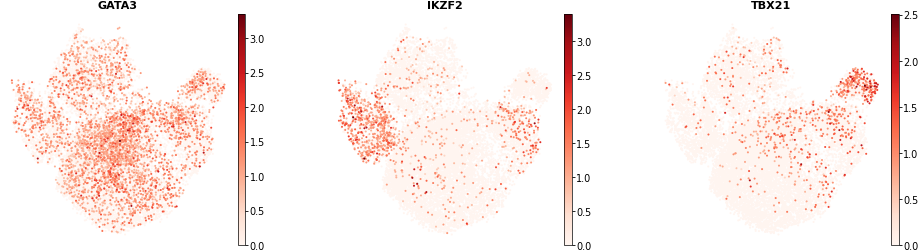

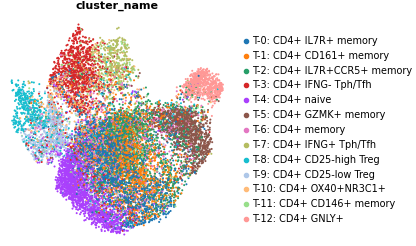

In [34]:
tf = adata[adata.obs["CTAP"] == TF_CTAP].copy()
tf.obs["cluster_name"] = pd.Categorical(tf.obs["cluster_name"])

plt.rcParams["figure.figsize"] = (3, 3)
sc.pl.umap(tf, color=GENES, layer=EXPR_LAYER, sort_order=True, cmap="Reds", frameon=False,
           vmin=0, ncols=3, show=False)
plt.savefig(f"{OUT_DIR}/{TAG}_umap_expression_TF.pdf", bbox_inches="tight")
plt.show()

sc.pl.umap(tf, color="cluster_name", frameon=False, show=False)
plt.savefig(f"{OUT_DIR}/{TAG}_umap_subset_TF.pdf", bbox_inches="tight")
plt.show()


### 3.2 Dot plot, T + F cells

Dot colour is mean `log1p_norm` among all cells of the subset, dot size the fraction of cells
with nonzero expression (the dot plot default).

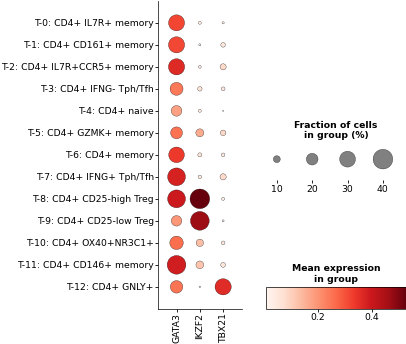

In [35]:
cluster_names = (tf.obs.drop_duplicates("cluster").set_index("cluster")["cluster_name"]
                 .reindex(AMP_ORDER))
tf.obs["cluster_label"] = pd.Categorical(tf.obs["cluster_name"], categories=cluster_names.tolist())
tf.X = tf.layers[EXPR_LAYER].copy()

dp = sc.pl.dotplot(tf, var_names=GENES, groupby="cluster_label", standard_scale=None,
                   cmap="Reds", dot_max=0.4, figsize=(3.2, 4), show=False, return_fig=True)
dp.savefig(f"{OUT_DIR}/{TAG}_dotplot_TF.pdf", bbox_inches="tight")
plt.show()

## 4. T-3, T-7 and T-4: donor-level pseudobulk, RA vs control

One value per donor x subset with at least `MIN_CELLS_PER_PSEUDOBULK` cells: mean `log1p_norm` for
each gene, for the `FOCAL` subsets T-3, T-7 and T-4.

In [36]:
foc = adata[adata.obs["cluster"].isin(FOCAL)].copy()
foc.obs["cluster"] = pd.Categorical(foc.obs["cluster"], categories=FOCAL)

cells = foc.obs[["subject_id", "cluster", "group"] + [f"{g}_expr" for g in GENES]].copy()

pb = (cells.groupby(["subject_id", "cluster", "group"], observed=True)
      .agg(n_cells=("GATA3_expr", "size"),
           **{f"{g}_mean": (f"{g}_expr", "mean") for g in GENES})
      .reset_index())
print(f"{len(pb)} donor x subset pairs | "
      f"{int((pb['n_cells'] >= MIN_CELLS_PER_PSEUDOBULK).sum())} with >= "
      f"{MIN_CELLS_PER_PSEUDOBULK} cells")
pb = pb[pb["n_cells"] >= MIN_CELLS_PER_PSEUDOBULK].copy()
pb["cluster"] = pd.Categorical(pb["cluster"], categories=FOCAL)
pb.to_csv(f"{OUT_DIR}/{TAG}_pseudobulk_focal.csv", index=False)

display(pb.groupby(["cluster", "group"], observed=True)
        .agg(donors=("subject_id", "nunique"), median_cells=("n_cells", "median"),
             **{m: (m, "median") for m in [f"{g}_mean" for g in GENES]}).round(4))

40 donor x subset pairs | 34 with >= 10 cells


donors  median_cells  GATA3_mean  IKZF2_mean  TBX21_mean
cluster group                                                            
T-3     control       5          34.0      0.2134      0.1093      0.0000
        RA            7         197.0      0.2371      0.0521      0.0290
T-4     control       5          17.0      0.2126      0.0486      0.0000
        RA            7         236.0      0.1750      0.0258      0.0092
T-7     control       3          35.0      0.2593      0.0000      0.0419
        RA            7          54.0      0.4050      0.0228      0.0641

### 4.1 Plots

Boxes are donors; points are individual donors.

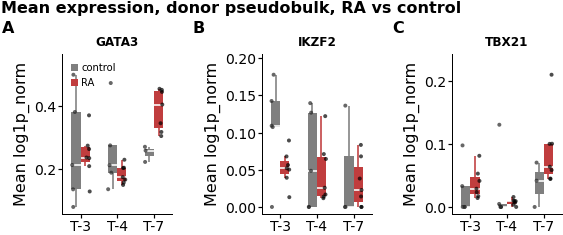

In [37]:
METRICS = [(f"{g}_mean", "Mean log1p_norm", g) for g in GENES]
FIGURES = [("expression", "Mean expression", METRICS)]

for fig_name, fig_title, fig_metrics in FIGURES:
    mp = cns.multipanel(max_width=1000, title=f"{fig_title}, donor pseudobulk, RA vs control",
                        title_fontweight="bold", loc="left")
    for label, (metric, ylab, title) in zip("ABCDEFGH", fig_metrics):
        mp.panel(label, 55, 80)
        ax = cns.boxplot(pb, x="cluster", y=metric, hue="group", order=FOCAL,
                         hue_order=[CONTROL, CASE], palette=GROUP_PALETTE, showoutliers=False)
        sns.stripplot(pb, x="cluster", y=metric, hue="group", order=FOCAL,
                      hue_order=[CONTROL, CASE], dodge=True, palette='dark:black', size=2, alpha=0.7,
                      legend=False, ax=ax)
        ax.set_xlabel("")
        ax.set_ylabel(ylab)
        ax.set_title(title, fontsize=6, fontweight="bold")
        pad_ymax(ax)
        if label == "A":
            handles, labels_ = ax.get_legend_handles_labels()
            ax.legend(handles[:2], labels_[:2], frameon=False, fontsize=5, loc="upper left")
        elif ax.get_legend():
            ax.get_legend().remove()
    cns.savefig(f"{OUT_DIR}/{TAG}_pseudobulk_{fig_name}_focal.pdf")

### 4.2 RA vs control within each subset

Mann-Whitney U (two-sided; different donors), per subset and metric. BH across the three subsets
within each metric. `delta_median` is RA minus control.

In [38]:
rows = []
for metric, *_ in METRICS:
    for cl in FOCAL:
        d = pb[pb["cluster"] == cl]
        a, b = d.loc[d["group"] == CASE, metric], d.loc[d["group"] == CONTROL, metric]
        p = (stats.mannwhitneyu(a, b, alternative="two-sided")[1]
             if len(a) > 0 and len(b) > 0 else np.nan)
        rows.append(dict(metric=metric, cluster=cl, n_RA=len(a), n_control=len(b),
                         median_RA=a.median(), median_control=b.median(),
                         delta_median=a.median() - b.median(), p_value=p))
group_stats = pd.DataFrame(rows)
group_stats["p_adj"] = (group_stats.groupby("metric")["p_value"]
                        .transform(lambda p: multipletests(p.fillna(1), method="fdr_bh")[1]))
group_stats.to_csv(f"{OUT_DIR}/{TAG}_ra_vs_control_mannwhitney.csv", index=False)
display(group_stats.round(4))

,metric,cluster,n_RA,n_control,median_RA,median_control,delta_median,p_value,p_adj
0,GATA3_mean,T-3,7,5,0.2371,0.2134,0.0237,1.0000,1.0000
1,GATA3_mean,T-4,7,5,0.1750,0.2126,-0.0377,0.3434,0.5152
2,GATA3_mean,T-7,7,3,0.4050,0.2593,0.1458,0.0167,0.0500
3,IKZF2_mean,T-3,7,5,0.0521,0.1093,-0.0571,0.1061,0.3182
4,IKZF2_mean,T-4,7,5,0.0258,0.0486,-0.0228,1.0000,1.0000
5,IKZF2_mean,T-7,7,3,0.0228,0.0000,0.0228,0.8141,1.0000
6,TBX21_mean,T-3,7,5,0.0290,0.0000,0.0290,0.3265,0.3265
7,TBX21_mean,T-4,7,5,0.0092,0.0000,0.0092,0.2826,0.3265
8,TBX21_mean,T-7,7,3,0.0641,0.0419,0.0222,0.1833,0.3265
